# CarDD · Mask R-CNN vs YOLO 对比表格 + 可视化

CA6129 课程项目 · Computer Vision & Applications

只从 Drive 里已经存过的结果 json 读数据，**完全不依赖训练过程**——不管 `01_MaskRCNN_train.ipynb` 和 `02_YOLO_train.ipynb` 是不是同一次跑的、隔了几天，只要各自跑完存过一次，这里都能拼出完整对比；如果只跑了一个，就只展示那一行并提示另一个还没跑。不需要开 GPU 运行时。

In [1]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [2]:
DRIVE_PROJECT_DIR = '/content/drive/MyDrive/CarDD_project'

import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

DRIVE_PROJECT_DIR = Path(DRIVE_PROJECT_DIR)
RESULTS_DRIVE_DIR = DRIVE_PROJECT_DIR / 'colab_results'
assert RESULTS_DRIVE_DIR.exists(), f'找不到结果目录: {RESULTS_DRIVE_DIR}，先跑至少一个训练 notebook'


In [3]:
rows = []
missing = []
for label, filename in [('Mask R-CNN', 'final_results_row_mask_rcnn.json'), ('YOLO Segmentation', 'final_results_row_yolo.json')]:
    path = RESULTS_DRIVE_DIR / filename
    if path.exists():
        rows.append(json.loads(path.read_text(encoding='utf-8')))
    else:
        missing.append(label)

if missing:
    print('还没有结果的方法（跑完对应 notebook 后重新运行这个 cell）:', ', '.join(missing))
if not rows:
    raise RuntimeError('Mask R-CNN 和 YOLO 都还没跑完，先跑至少一个再来生成对比表格')

comparison_df = pd.DataFrame(rows).set_index('method')
comparison_df = comparison_df[['mask_iou', 'precision', 'recall', 'mAP50', 'mAP50_95', 'latency_ms',
                                'box_precision', 'box_recall', 'matched_pairs', 'unmatched_predictions']]
comparison_df.round(4)


,mask_iou,precision,recall,mAP50,mAP50_95,latency_ms,box_precision,box_recall,matched_pairs,unmatched_predictions
method,,,,,,,,,,
Mask R-CNN,0.7965,0.6240,0.7467,0.7107,0.5092,139.8583,0.6339,0.7574,542,374
YOLO Segmentation,0.8163,0.8156,0.6321,0.6044,0.4741,13.5000,0.8047,0.6267,425,121


In [4]:
display_df = comparison_df[['mask_iou', 'precision', 'recall', 'mAP50', 'mAP50_95', 'latency_ms']].round(4)
styled = display_df.style.set_caption('CarDD test split (374 张), conf=0.5, IoU match=0.5').format(precision=4)
if len(display_df) > 1:
    styled = (styled
        .highlight_max(subset=['mask_iou', 'precision', 'recall', 'mAP50', 'mAP50_95'], color='#c6efce')
        .highlight_min(subset=['latency_ms'], color='#c6efce'))
styled


,mask_iou,precision,recall,mAP50,mAP50_95,latency_ms
method,,,,,,
Mask R-CNN,0.7965,0.6240,0.7467,0.7107,0.5092,139.8583
YOLO Segmentation,0.8163,0.8156,0.6321,0.6044,0.4741,13.5000


/tmp/ipykernel_3159/3464045328.py:34: UserWarning: Glyph 20998 (\N{CJK UNIFIED IDEOGRAPH-5206}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3159/3464045328.py:34: UserWarning: Glyph 21106 (\N{CJK UNIFIED IDEOGRAPH-5272}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3159/3464045328.py:34: UserWarning: Glyph 36136 (\N{CJK UNIFIED IDEOGRAPH-8D28}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3159/3464045328.py:34: UserWarning: Glyph 37327 (\N{CJK UNIFIED IDEOGRAPH-91CF}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3159/3464045328.py:34: UserWarning: Glyph 25351 (\N{CJK UNIFIED IDEOGRAPH-6307}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3159/3464045328.py:34: UserWarning: Glyph 26631 (\N{CJK UNIFIED IDEOGRAPH-6807}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3159/3464045328.py:34: UserWarning: Glyph 23545 (\N{CJK UNIFIED IDEOGRAPH-5BF9}

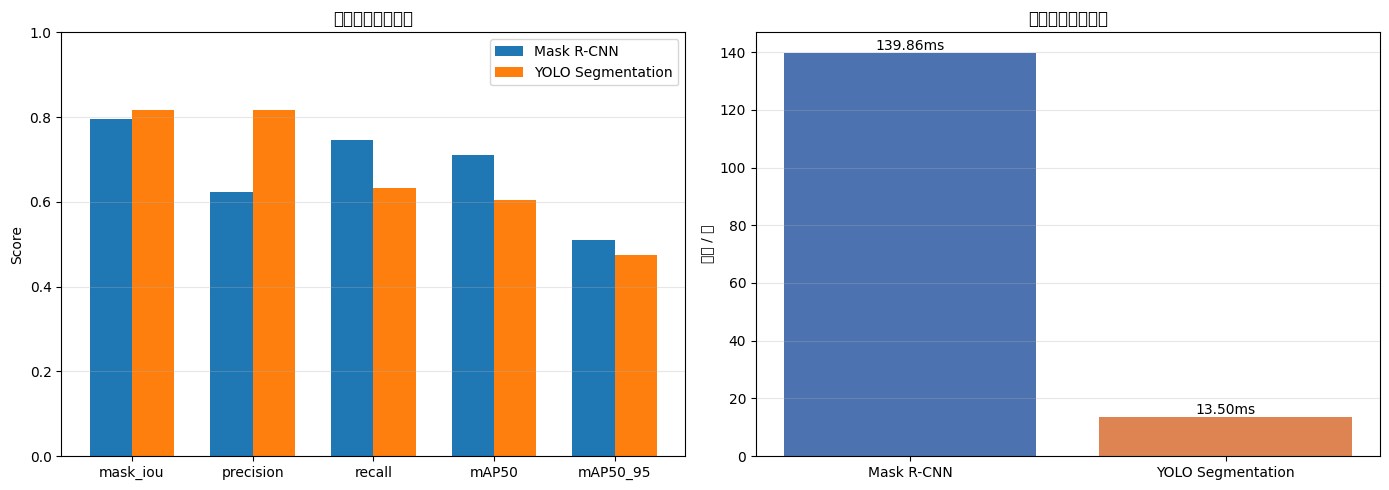

In [5]:
# 只有两个方法都跑完才画对比图；只跑了一个的话跳过这个 cell，等另一个跑完再回来跑
if len(comparison_df) < 2:
    print('只有一个方法的结果，跳过对比图。')
else:
    metrics = ['mask_iou', 'precision', 'recall', 'mAP50', 'mAP50_95']
    methods = comparison_df.index.tolist()
    x = np.arange(len(metrics))
    width = 0.35

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    ax = axes[0]
    for i, method in enumerate(methods):
        values = comparison_df.loc[method, metrics].values.astype(float)
        ax.bar(x + (i - 0.5) * width, values, width, label=method)
    ax.set_xticks(x)
    ax.set_xticklabels(metrics)
    ax.set_ylim(0, 1)
    ax.set_ylabel('Score')
    ax.set_title('分割质量指标对比')
    ax.legend()
    ax.grid(axis='y', alpha=0.3)

    ax = axes[1]
    latency_values = comparison_df['latency_ms'].astype(float)
    bars = ax.bar(methods, latency_values, color=['#4c72b0', '#dd8452'])
    ax.set_ylabel('毫秒 / 张')
    ax.set_title('单张图片推理延迟')
    ax.grid(axis='y', alpha=0.3)
    for bar, value in zip(bars, latency_values):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f'{value:.2f}ms',
                ha='center', va='bottom')

    plt.tight_layout()
    plt.savefig(RESULTS_DRIVE_DIR / 'comparison_chart.png', dpi=150, bbox_inches='tight')
    plt.show()


/tmp/ipykernel_3159/3057498864.py:18: UserWarning: Glyph 21508 (\N{CJK UNIFIED IDEOGRAPH-5404}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3159/3057498864.py:18: UserWarning: Glyph 25439 (\N{CJK UNIFIED IDEOGRAPH-635F}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3159/3057498864.py:18: UserWarning: Glyph 20260 (\N{CJK UNIFIED IDEOGRAPH-4F24}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3159/3057498864.py:18: UserWarning: Glyph 31867 (\N{CJK UNIFIED IDEOGRAPH-7C7B}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3159/3057498864.py:18: UserWarning: Glyph 21035 (\N{CJK UNIFIED IDEOGRAPH-522B}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3159/3057498864.py:18: UserWarning: Glyph 23545 (\N{CJK UNIFIED IDEOGRAPH-5BF9}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3159/3057498864.py:18: UserWarning: Glyph 27604 (\N{CJK UNIFIED IDEOGRAPH-6BD4}

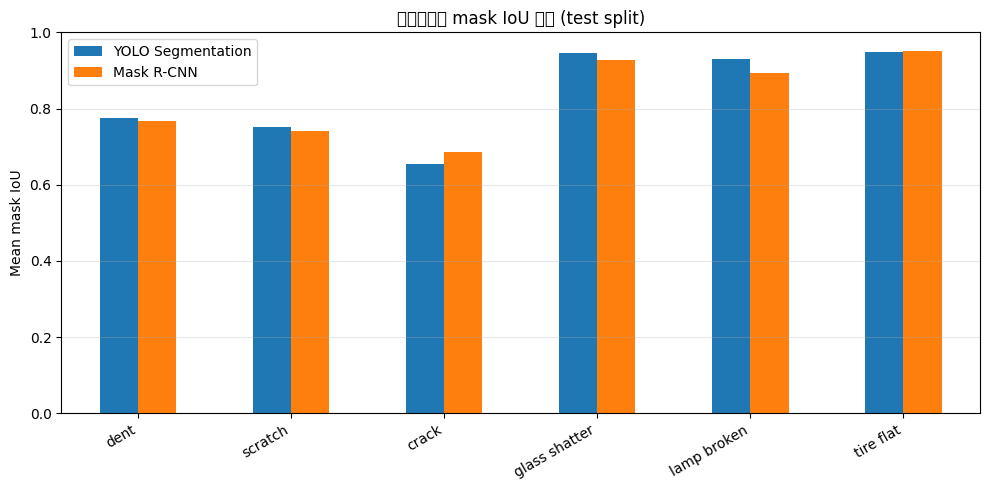

,YOLO Segmentation,Mask R-CNN
dent,0.7747,0.7672
scratch,0.7522,0.7397
crack,0.6555,0.6862
glass shatter,0.9461,0.9285
lamp broken,0.9289,0.8936
tire flat,0.9496,0.9511


In [6]:
# 各损伤类别的 mask IoU 对比，同样要两个方法都跑完才有意义
if len(comparison_df) < 2:
    print('只有一个方法的结果，跳过这张图。')
else:
    yolo_iou = json.loads((RESULTS_DRIVE_DIR / 'yolo_mask_iou_summary.json').read_text(encoding='utf-8'))
    mask_rcnn_iou = json.loads((RESULTS_DRIVE_DIR / 'mask_rcnn_mask_iou_summary.json').read_text(encoding='utf-8'))

    per_class_df = pd.DataFrame({
        'YOLO Segmentation': yolo_iou['per_class_mean_mask_iou'],
        'Mask R-CNN': mask_rcnn_iou['per_class_mean_mask_iou'],
    })

    ax = per_class_df.plot(kind='bar', figsize=(10, 5), ylim=(0, 1))
    ax.set_ylabel('Mean mask IoU')
    ax.set_title('各损伤类别 mask IoU 对比 (test split)')
    ax.grid(axis='y', alpha=0.3)
    plt.xticks(rotation=30, ha='right')
    plt.tight_layout()
    plt.savefig(RESULTS_DRIVE_DIR / 'per_class_iou_chart.png', dpi=150, bbox_inches='tight')
    plt.show()
    display(per_class_df.round(4))


---

**结果文件说明**（都存在 `MyDrive/CarDD_project/colab_results/` 里）

| 文件 | 内容 |
|---|---|
| `final_results_row_yolo.json` / `final_results_row_mask_rcnn.json` | 对比表格每一行的原始数据 |
| `yolo_mask_iou_summary.json` / `mask_rcnn_mask_iou_summary.json` | 各方法的 mask IoU、per-class IoU、错误类型统计 |
| `comparison_chart.png` / `per_class_iou_chart.png` | 上面两张图，可以直接放进报告 |
| `yolo_best.pt` / `mask_rcnn_final.pt` | 训练好的权重 |
| `manifests/cardd_manifest.json`（在 `CarDD_project/manifests/`，不在 `colab_results/`） | 两个方法共用的 ground truth 索引，生成一次后所有 notebook/session 都复用 |
